# Task 7 - Contract vs EOA Activity

## Analytical Question

**What type of transaction activity dominated Ethereum during the period?**

### Workflow

**BigQuery → GoogleSQL → Analytical Dataset → Pandas → Analysis → Visualization → Insight**

## Data source

Google Cloud BigQuery Ethereum Mainnet Blockchain Analytics dataset:
- **Source dataset:** `bigquery-public-data.goog_blockchain_ethereum_mainnet_us`
- **Source table:** `transactions`, `logs` , `traces`
- SQL: `sql/07_contract_vs_eoa.sql`

For this analysis, exact historical recipient-level EOA/contract classification was not used because the available historical account-state approach was too expensive to query in BigQuery.

Instead, we use observable contract activity:

- **Contract-interaction transactions:** transactions with at least one non-removed log.
- **Contract-creation transactions:** transactions with at least one `create` trace.
- **Transactions without observed logs:** residual transactions with no non-removed log. These are **not** classified as EOA-to-EOA.

Contract-interaction and contract-creation measures can overlap and therefore must not be added together.

### Analysis window

- Start: **2026-08-24 10:01:35 UTC**
- End: **2026-09-23 10:01:35 UTC**
- Duration: **30 days**
- Start block: **25,824,304**
- End block: **26,039,452**

The first and last calendar dates are partial days because the window starts and ends at 10:01:35 UTC.



In [101]:
import pandas as pd
import matplotlib.pyplot as plt

import pandas.io.formats.format as pf
# Force Pandas' internal integer formatter to use commas seperator globally
class CommaIntFormatter(pf._GenericArrayFormatter):
    def _format_strings(self):
        formatter = self.formatter or '{:,d}'.format
        return [formatter(x) for x in self.values]

# Override the default engine
pf._IntArrayFormatter = CommaIntFormatter

# Format float with comma(removes E-notation)
pd.set_option('display.float_format', lambda x: f' {x:,.2f}')

## 1. Load the Analytical Dataset


In [79]:

df = pd.read_csv("../data/processed/daily_contract_activity.csv")

df["date"] = pd.to_datetime(df["date"])

df.head()

,date,total_transactions,contract_interaction_transactions,contract_creation_transactions,transactions_without_observed_logs
0,2026-08-24,"1,157,222","734,744","6,554","422,478"
1,2026-08-25,"1,994,723","1,248,232","11,652","746,491"
2,2026-08-26,"1,898,276","1,224,565","11,446","673,711"
3,2026-08-27,"1,931,985","1,242,676","10,593","689,309"
4,2026-08-28,"1,902,964","1,235,731","10,915","667,233"


## 2. Validate the Dataset

Check the row count, columns, missing values, duplicate dates, and analysis window.


In [41]:
print("Shape:", df.shape)

print("\nMissing values:")
print(df.isna().sum())

print("\nDuplicate dates:", df["date"].duplicated().sum())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())


Shape: (31, 5)

Missing values:
date                                 0
total_transactions                   0
contract_interaction_transactions    0
contract_creation_transactions       0
transactions_without_observed_logs   0
dtype: int64

Duplicate dates: 0

Date range:
2026-08-24 00:00:00 to 2026-09-23 00:00:00


## Partial-Day Handling

The exact analysis window produces 31 calendar dates. The first and last dates are partial days and are excluded from comparable-day statistics.


In [42]:
# The two partial days
first_date = df["date"].min()
last_date = df["date"].max()

# keep only complete days 
complete_days = df[
    (df["date"] > first_date)
    & (df["date"] < last_date)
].copy()

complete_days.shape

(29, 5)

## 3. Analytical Metrics

The daily percentage of transactions with observed contract interaction and the daily contract-creation rate.


In [43]:
complete_days["contract_interaction_rate_pct"] = (
    complete_days["contract_interaction_transactions"]
    / complete_days["total_transactions"]
    * 100
)

complete_days["contract_creation_rate_pct"] = (
    complete_days["contract_creation_transactions"]
    / complete_days["total_transactions"]
    * 100
)

complete_days[
    [
        "date",
        "total_transactions",
        "contract_interaction_transactions",
        "contract_creation_transactions",
        "contract_interaction_rate_pct",
        "contract_creation_rate_pct",
    ]
].head()


,date,total_transactions,contract_interaction_transactions,contract_creation_transactions,contract_interaction_rate_pct,contract_creation_rate_pct
1,2026-08-25,"1,994,723","1,248,232","11,652",62.58,0.58
2,2026-08-26,"1,898,276","1,224,565","11,446",64.51,0.60
3,2026-08-27,"1,931,985","1,242,676","10,593",64.32,0.55
4,2026-08-28,"1,902,964","1,235,731","10,915",64.94,0.57
5,2026-08-29,"2,034,340","972,272","9,778",47.79,0.48


## 4. Period-Level Summary
The overall transaction counts and rates for the complete analysis window.


In [44]:
total_transactions = complete_days["total_transactions"].sum()
contract_interactions = complete_days["contract_interaction_transactions"].sum()
contract_creations = complete_days["contract_creation_transactions"].sum()

contract_interaction_rate = contract_interactions / total_transactions * 100
contract_creation_rate = contract_creations / total_transactions * 100

print(f"Total transactions: {total_transactions:,}")
print(f"Contract-interaction transactions: {contract_interactions:,}")
print(f"Contract-interaction rate: {contract_interaction_rate:.2f}%")
print(f"Contract-creation transactions: {contract_creations:,}")
print(f"Contract-creation rate: {contract_creation_rate:.2f}%")


Total transactions: 55,151,035
Contract-interaction transactions: 35,024,739
Contract-interaction rate: 63.51%
Contract-creation transactions: 299,259
Contract-creation rate: 0.54%


## 5. Visualization - Contract Interaction Activity

Lets see the daily share of transactions with an observed contract interaction.

Note: this is based on transactions with at least one non-removed log. It does not capture every possible contract interaction.

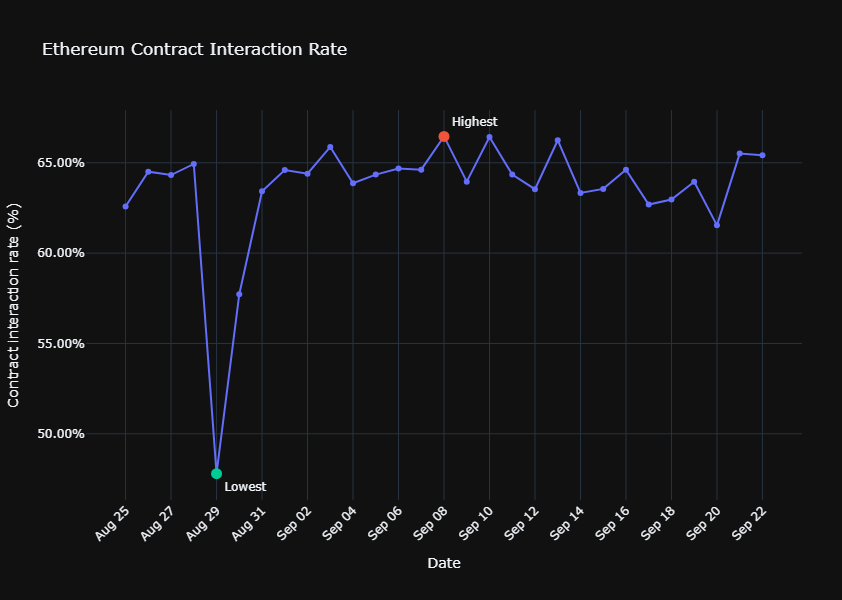

In [88]:

# Identify highest and lowest interaction-rate days
highest_day = complete_days.loc[
    complete_days["contract_interaction_rate_pct"].idxmax()
]

lowest_day = complete_days.loc[
    complete_days["contract_interaction_rate_pct"].idxmin()
]


# Create the line chart
fig = px.line(
    complete_days,
    x="date",
    y="contract_interaction_rate_pct",
    title="Ethereum Contract Interaction Rate",
    markers=True,
    labels={
        "date": "Date",
        "contract_interaction_rate_pct": "Contract interaction rate (%)"
    }
)


# Chart layout
fig.update_layout(
    template="plotly_dark",
    hovermode="x unified",
    height=600,

    margin=dict(
        l=70,
        r=40,
        t=110,
        b=100
    ),

    xaxis=dict(
        title="Date",
        hoverformat="%b %d, %Y",
        nticks=20,
        tickformat="%b %d",
        tickangle=-45
    ),

    yaxis=dict(
        title="Contract interaction rate (%)",
        ticksuffix="%",
        tickformat=".2f",
        fixedrange=True
    ),

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    )
)


# Format markers and hover information
fig.update_traces(
    marker=dict(size=6),
    hovertemplate=(
        "%{y:.2f}%"
        "<extra></extra>"
    )
)


# Add highest interaction-rate marker
fig.add_scatter(
    x=[highest_day["date"]],
    y=[highest_day["contract_interaction_rate_pct"]],
    mode="markers+text",
    text=["Highest"],
    textposition="top right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Highest interaction rate</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.2f}%"
        "<extra></extra>"
    )
)


# Add lowest interaction-rate marker
fig.add_scatter(
    x=[lowest_day["date"]],
    y=[lowest_day["contract_interaction_rate_pct"]],
    mode="markers+text",
    text=["Lowest"],
    textposition="bottom right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Lowest interaction rate</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.2f}%"
        "<extra></extra>"
    )
)


fig.show()

## 6. Contract Creation Activity

Lets visualize the daily rate of transactions associated with contract creation.


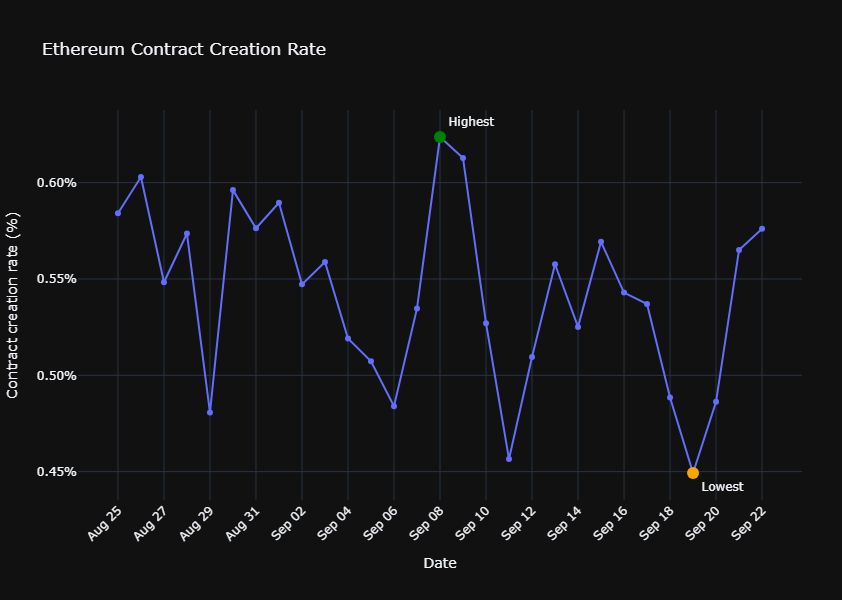

In [100]:

# Identify highest and lowest creation-rate days
highest_day = complete_days.loc[
    complete_days["contract_creation_rate_pct"].idxmax()
]

lowest_day = complete_days.loc[
    complete_days["contract_creation_rate_pct"].idxmin()
]


# Create the line chart
fig = px.line(
    complete_days,
    x="date",
    y="contract_creation_rate_pct",
    title="Ethereum Contract Creation Rate",
    markers=True,
    labels={
        "date": "Date",
        "contract_creation_rate_pct": "Contract creation rate (%)"
    }
)


# Chart layout
fig.update_layout(
    template="plotly_dark",
    hovermode="x unified",
    height=600,

    margin=dict(
        l=70,
        r=40,
        t=110,
        b=100
    ),

    xaxis=dict(
        title="Date",
        hoverformat="%b %d, %Y",
        nticks=20,
        tickformat="%b %d",
        tickangle=-45
    ),

    yaxis=dict(
        title="Contract creation rate (%)",
        ticksuffix="%",
        tickformat=".2f",
        fixedrange=True
    ),

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    )
)


# Format markers and hover information
fig.update_traces(
    marker=dict(size=6),
    hovertemplate=(
        "%{y:.2f}%"
        "<extra></extra>"
    )
)


# Add highest creation-rate marker
fig.add_scatter(
    x=[highest_day["date"]],
    y=[highest_day["contract_creation_rate_pct"]],
    mode="markers+text",
    text=["Highest"],
    textposition="top right",
    marker=dict(size=12, color="green"),
    showlegend=False,
    hovertemplate=(
        "<b>Highest creation rate</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.2f}%"
        "<extra></extra>"
    )
)


# Add lowest creation-rate marker
fig.add_scatter(
    x=[lowest_day["date"]],
    y=[lowest_day["contract_creation_rate_pct"]],
    mode="markers+text",
    text=["Lowest"],
    textposition="bottom right",
    marker=dict(size=12, color="orange"),
    showlegend=False,
    hovertemplate=(
        "<b>Lowest creation rate</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.2f}%"
        "<extra></extra>"
    )
)


fig.show()

## 7. Baseline Statistics

Summary of the daily contract-interaction and contract-creation rates.


In [47]:
summary = pd.DataFrame({
    "metric": [
        "Contract-interaction rate",
        "Contract-creation rate"
    ],
    "mean_pct": [
        complete_days["contract_interaction_rate_pct"].mean(),
        complete_days["contract_creation_rate_pct"].mean()
    ],
    "min_pct": [
        complete_days["contract_interaction_rate_pct"].min(),
        complete_days["contract_creation_rate_pct"].min()
    ],
    "max_pct": [
        complete_days["contract_interaction_rate_pct"].max(),
        complete_days["contract_creation_rate_pct"].max()
    ]
})

summary


,metric,mean_pct,min_pct,max_pct
0,Contract-interaction rate,63.53,47.79,66.46
1,Contract-creation rate,0.54,0.45,0.62


## 8. Highest and Lowest Activity Days


In [78]:
interaction_high = complete_days.loc[complete_days["contract_interaction_rate_pct"].idxmax()]
interaction_low = complete_days.loc[complete_days["contract_interaction_rate_pct"].idxmin()]

creation_high = complete_days.loc[complete_days["contract_creation_rate_pct"].idxmax()]
creation_low = complete_days.loc[complete_days["contract_creation_rate_pct"].idxmin()]

print(f"Highest contract-interaction rate: {interaction_high['date'].date()} — {interaction_high['contract_interaction_rate_pct']:.2f}%")
print(f"Lowest contract-interaction rate: {interaction_low['date'].date()} — {interaction_low['contract_interaction_rate_pct']:.2f}%")

print(f"Highest contract-creation rate: {creation_high['date'].date()} — {creation_high['contract_creation_rate_pct']:.2f}%")
print(f"Lowest contract-creation rate: {creation_low['date'].date()} — {creation_low['contract_creation_rate_pct']:.2f}%")

Highest contract-interaction rate: 2026-09-08 — 66.46%
Lowest contract-interaction rate: 2026-08-29 — 47.79%
Highest contract-creation rate: 2026-09-08 — 0.62%
Lowest contract-creation rate: 2026-09-19 — 0.45%


## Finding | Evidence | Meaning

### Finding


*Observable contract activity accounted for a substantial share of Ethereum transactions during the 29 complete days analyzed, while contract creation represented a much smaller share of transaction activity.*

### Evidence

- The analysis excludes the first and last calendar dates dynamically, leaving **29 complete days** for the daily analysis.
- **55,151,035** transactions were recorded across the complete days.
- **35,024,739** transactions had at least one non-removed log, representing **63.51%** of transactions.
- Contract-interaction rate averaged **63.53%** per complete day, ranging from **47.79%** to **66.46%**.
- The highest daily contract-interaction rate was **September 8, 2026 — 66.46%**.
- The lowest daily contract-interaction rate was **August 29, 2026 — 47.79%**.
- **299,259** transactions were associated with at least one `create` trace, representing **0.54%** of transactions.
- Contract-creation rate averaged **0.54%** per complete day, ranging from **0.45%** to **0.62%**.
- The highest daily contract-creation rate was **September 8, 2026 — 0.62%**.
- The lowest daily contract-creation rate was **September 19, 2026 — 0.45%**.
- Contract-interaction and contract-creation measures can overlap, so their percentages **must not be added together**.
- Transactions without observed logs are **not classified as EOA-to-EOA activity**.

### Meaning

The results show that **transactions with observable contract-event activity were common during the period**, while transactions associated with contract creation were comparatively rare.

The analysis deliberately uses observable logs and `create` traces rather than assuming an address is an EOA or contract. Therefore, transactions without observed logs cannot be interpreted as EOA-to-EOA activity, and the results do not provide an exact recipient-level EOA-versus-contract classification for every transaction.

## Methodology Limitations

- **Exact recipient-level EOA vs. contract classification was not performed** because the historical account-state approach was too expensive to query for this 30-day analysis.

- The analysis therefore reports **observable contract activity** using:
  - transactions with at least one **non-removed log**; and
  - transactions associated with a **`create` trace**.

- **Observed logs are a proxy for contract-related activity, not a complete measure of all contract interactions.** A transaction can interact with a contract without producing a log/event.

- **Contract-interaction and contract-creation transactions are not mutually exclusive.** A contract-creation transaction may also emit logs. Therefore, their percentages **must not be added together** to estimate the total share of contract activity.

- **Transactions without observed logs are not classified as EOA-to-EOA activity.** The absence of a log does not prove that a transaction involved only EOAs.

- The analysis is therefore based on **observable transaction-level evidence**, rather than a complete historical classification of every transaction recipient as an EOA or contract.

- For daily comparisons and descriptive statistics, the **first and last calendar dates are excluded because they are partial days.

- These limitations should be considered when interpreting the findings and should not be treated as evidence of causation.